<a href="https://colab.research.google.com/github/ipr2104/Advanced-Quant/blob/main/Homework4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 5. Following the hands on activity in the lecture, partition the uncertainty in projections of decadal mean British Isles annual temperature into internal variability (I), model uncertainty (M) and scenario uncertainty (S)

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]

In [2]:
# Read data (rows = years, columns = models) and make anomalies
data = {}
for s in scenarios:
    df = pd.read_csv(f"cmip6_britishisles_tas_{s}.csv", index_col="year")

    data[s] = df - df.loc[1995:2014].mean()      # anomaly relative to 1995-2014

models = data["ssp585"].columns
years = data["ssp585"].index.values

In [3]:
# rescaled time for a stable fit
x = (years - years.mean()) / years.std()
# columns: 1, x, x², x³, x⁴ (fourth order polynomial)
X = np.column_stack([x**k for k in range(4 + 1)])   # columns: 1, x, x², x³, x⁴
X[0,:]


array([ 1.        , -1.72054204,  2.9602649 , -5.0932602 ,  8.76316828])

In [4]:
F = {}
for s in scenarios:
    F[s] = pd.DataFrame(index=years, columns=models, dtype=float)
    for m in models:
        res = sm.OLS(data[s][m].values, X).fit()
        F[s][m] = res.fittedvalues

    ### all forced responses is reletive to 1995 to 2014 mean (optional)
    F[s] = F[s] - F[s].loc[1995:2014].mean()

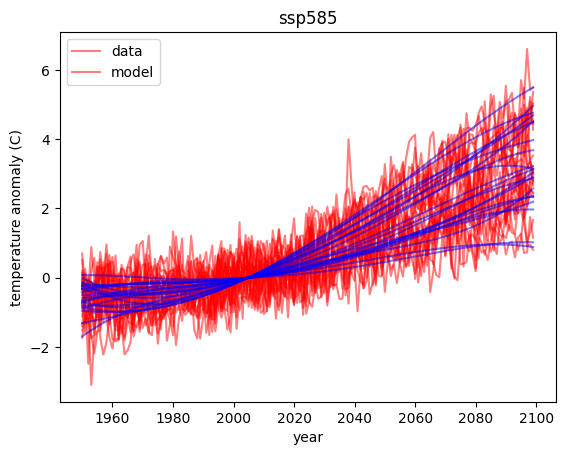

In [5]:
### check results using the last ssp in the scnearios
plt.plot(years,data[s],'r',alpha=0.5);
plt.plot(years,F[s],'b',alpha=0.5);
plt.title(s)
plt.xlabel("year")
plt.ylabel("temperature anomaly (C)")
plt.legend(["data","model"])


In [6]:
# Internal variability
I_values = []
for s in scenarios:
    resid = (data[s] - F[s]).rolling(10, center=True).mean()
    I_values.extend(resid.var(axis=0))          # variance over time, per model
I = np.mean(I_values)                           # single number (K^2), constant in time
print("Internal variability:", I)

Internal variability: 0.03518190142592697


1950    0.178832
1951    0.165866
1952    0.154665
1953    0.145012
1954    0.136706
          ...   
2095    1.366242
2096    1.401685
2097    1.438769
2098    1.477677
2099    1.518609
Length: 150, dtype: float64


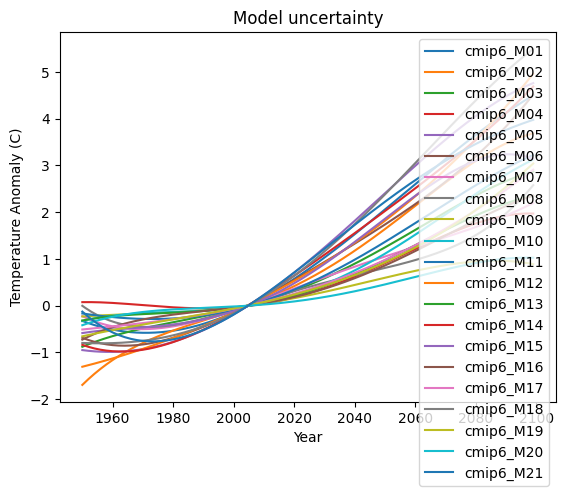

In [7]:
# Model uncertainty
M = F["ssp585"].var(axis=1, ddof=0) # population; CMIP6 is an ensmelbe of possibility not a random sample of all possible models.

plt.plot(F["ssp585"])
plt.legend(models)
plt.title("Model uncertainty")
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (C)")

print(M)

1950    0.003096
1951    0.003244
1952    0.003421
1953    0.003613
1954    0.003810
          ...   
2095    1.027190
2096    1.060642
2097    1.094380
2098    1.128375
2099    1.162595
Length: 150, dtype: float64


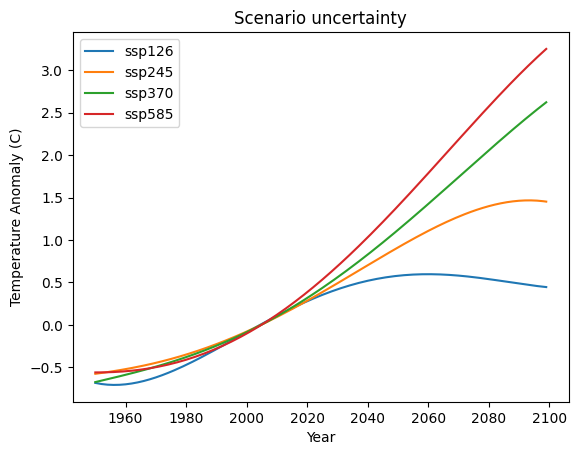

In [8]:
# Scenario uncerainty
scen_means = pd.DataFrame({s: F[s].mean(axis=1) for s in scenarios})
S = scen_means.var(axis=1, ddof=0)

plt.plot(scen_means);
plt.legend(scenarios);
plt.title("Scenario uncertainty")
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (C)")

print(S)

In [9]:
# Fractions of total variance
T = I + M + S
frac = pd.DataFrame({"Internal": I / T, "Model": M / T, "Scenario": S / T}) * 100

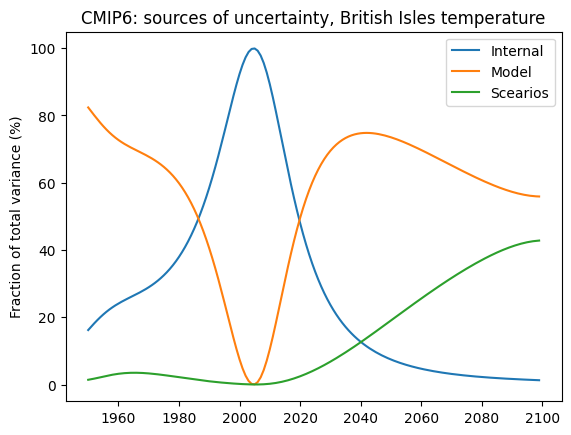

In [10]:
plt.plot(years,frac['Internal'],label = 'Internal')
plt.plot(years,frac['Model'],label = "Model")
plt.plot(years,frac['Scenario'],label = "Scearios")
plt.title("CMIP6: sources of uncertainty, British Isles temperature")
plt.legend()
plt.ylabel("Fraction of total variance (%)")
plt.xlim()
plt.savefig('CMIP6.png',dpi = 200)

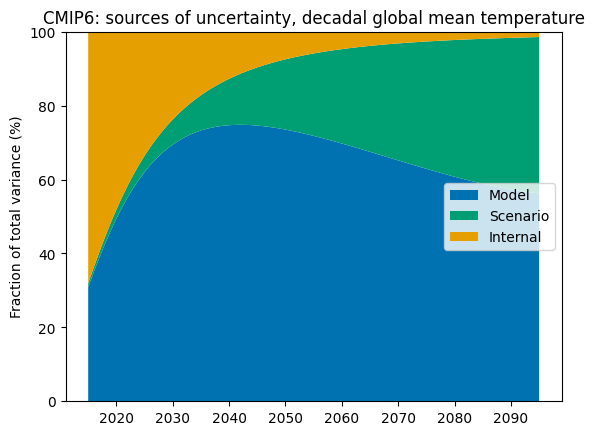

In [11]:
# simple plot of the fractions, 2015-2095
f = frac.loc[2015:2095]
plt.stackplot(f.index, f["Model"], f["Scenario"], f["Internal"],
              labels=["Model", "Scenario", "Internal"],
              colors=["#0072B2", "#009E73", "#E69F00"])
plt.ylim(0, 100)
plt.ylabel("Fraction of total variance (%)")
plt.title("CMIP6: sources of uncertainty, decadal global mean temperature")
plt.legend(loc="center right")
plt.savefig("cmip6_fractions.png", dpi=150)
plt.show()

In [ ]:
print(f"Internal fraction 2050 (%): {frac.loc[2050, 'Internal']:.3f}")
print(f"Model fraction 2050 (%): {frac.loc[2050, 'Model']:.3f}")

Internal fraction 2050 (%): 7.470
Model fraction 2050 (%): 73.507


a. Compare the results with the global mean temperature results from the class exercise. Complete the table below.

In [12]:
# Decadal SD of internal variability
sqrt_I = np.sqrt(I)
print(f"Internal variability (sqrt): {sqrt_I:.3f}")

# Uncertainty fractions
internal_2030_frac = frac.loc[2030, 'Internal']
model_2030_frac = frac.loc[2030, 'Model']
scenario_2030_frac = frac.loc[2030, 'Scenario']

print(f"Internal fraction 2030 (%): {internal_2030_frac:.3f}")
print(f"Model fraction 2030 (%): {model_2030_frac:.3f}")
print(f"Scenario fraction 2030 (%): {scenario_2030_frac:.3f}")

# First year after 2015 when internal uncertainty < 10%
first_year_after_2015 = frac.loc[2016:, 'Internal']
first_year_below_10 = first_year_after_2015[first_year_after_2015 < 10].index[0]
print(f"First year with internal fraction below 10% after 2015: {first_year_below_10}")

# Forced signal in 2050 under ssp585
forced_signal_2050 = F["ssp585"].loc[2050].mean()
print(f"Forced signal (multimodel mean of F) 2050: {forced_signal_2050:.3f}")

Internal variability (sqrt): 0.188
Internal fraction 2030 (%): 23.742
Model fraction 2030 (%): 69.460
Scenario fraction 2030 (%): 6.799
First year with internal fraction below 10% after 2015: 2045
Forced signal (multimodel mean of F) 2050: 1.399


### Notes
- Internal variability is larger for the British Isles with the decadal SD as 0.188 K
- Natural variability has a larger effect on decadal temperature projections
- Model uncertainty is nearly the same in 2030
- Scenario uncertainty is much smaller in 2030 so differences in SSPs contribute less to uncertainty here (near term)
- Internal variability isn't under 10% until 2045 so it takes longer for the forcing to differentiate from natural variability in these projections
- Forced warming signal is smaller in British Isles

c. Repeat the partitioning for the British Isles using annual instead of decadal-mean
temperature. How do I and the internal-variability fraction in 2030 change? Use your
results to explain why multi-year (e.g., decadal) means are commonly used when
partitioning projection uncertainty

In [13]:
# Internal variability annual
I_values = []
for s in scenarios:
    resid = (data[s] - F[s])
    I_values.extend(resid.var(axis=0))          # variance over time, per model
I = np.mean(I_values)                           # single number (K^2), constant in time
print("Internal variability:", I)

Internal variability: 0.2882038401320741


In [14]:
# Model uncertainty annual
M = F["ssp585"].var(axis=1, ddof=0)

In [15]:
# Scenario uncertainty annual
scen_means = pd.DataFrame({s: F[s].mean(axis=1) for s in scenarios})
S = scen_means.var(axis=1, ddof=0)

In [16]:
# Fractions of total variance
T = I + M + S
frac = pd.DataFrame({"Internal": I / T, "Model": M / T, "Scenario": S / T}) * 100

In [17]:
# Annual SD of internal variability
sqrt_I_annual = np.sqrt(I)
print(f"Internal variability (sqrt): {sqrt_I_annual:.3f}")

# Annual uncertainty fractions
internal_2030_frac_annual = frac.loc[2030, 'Internal']
model_2030_frac_annual = frac.loc[2030, 'Model']
scenario_2030_frac_annual = frac.loc[2030, 'Scenario']

print(f"Internal fraction 2030 (%): {internal_2030_frac_annual:.3f}")
print(f"Model fraction 2030 (%): {model_2030_frac_annual:.3f}")
print(f"Scenario fraction 2030 (%): {scenario_2030_frac_annual:.3f}")

# First year after 2015 when internal uncertainty < 10%
first_year_after_2015_annual = frac.loc[2016:, 'Internal']
first_year_below_10_annual = first_year_after_2015_annual[first_year_after_2015_annual < 10].index[0]
print(f"First year with internal fraction below 10% after 2015: {first_year_below_10_annual}")

# Forced signal in 2050 under ssp585
forced_signal_2050_annual = F["ssp585"].loc[2050].mean()
print(f"Forced signal (multimodel mean of F) 2050: {forced_signal_2050_annual:.3f}")

Internal variability (sqrt): 0.537
Internal fraction 2030 (%): 71.834
Model fraction 2030 (%): 25.655
Scenario fraction 2030 (%): 2.511
First year with internal fraction below 10% after 2015: 2098
Forced signal (multimodel mean of F) 2050: 1.399


### Notes
- SD of I is larger (no decadal smoothing)
- Internal fraction in 2030 is larger
- Model fraction in 2030 is smaller
- Scenario fraction 2030 is smaller
- First year with internal fraction below 10% is much later
- Forced signal stays the same becuase the temperatures are the same

## 6. Conduct a PCA of SST over the tropical Pacific (20°S–20°N, 120°E–80°W) and compare the results with those from the global PCA in the lecture


Hint: Use the class example, but restrict the domain to the tropical Pacific (20°S–20°N,
120°E–80°W).

a. Fill in the table below

In [18]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

In [19]:
# annual means, 1901–2004
ds = xr.open_dataset("HadISST.nc")
# (year, lat, lon)
sst  = ds["sst"].values
lat  = ds["latitude"].values
lon  = ds["longitude"].values
year = ds["year"].values.astype(int)
print(sst.shape)
ds

(104, 180, 360)


<xarray.Dataset> Size: 27MB
Dimensions:    (year: 104, latitude: 180, longitude: 360)
Coordinates:
  * year       (year) int64 832B 1901 1902 1903 1904 ... 2001 2002 2003 2004
  * latitude   (latitude) float32 720B -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * longitude  (longitude) float32 1kB 0.5 1.5 2.5 3.5 ... 357.5 358.5 359.5
Data variables:
    sst        (year, latitude, longitude) float32 27MB nan nan nan ... nan nan

/tmp/ipykernel_1078/4273623585.py:17: RuntimeWarning: Mean of empty slice
  Y = Y - np.nanmean(Y, axis=0)


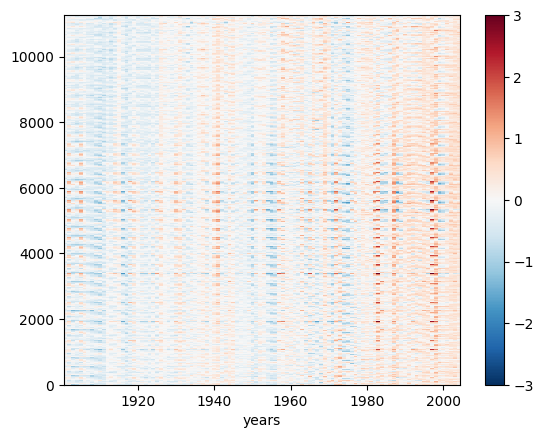

In [20]:
# Re-load original variables to avoid working with empty arrays from previous run
sst = ds["sst"].values
lat = ds["latitude"].values
lon = ds["longitude"].values

# Slice for the tropical Pacific (20S-20N, 120E-80W)
lat_mask = (lat >= -20) & (lat <= 20)
lon_mask = (lon >= 120) | (lon <= 280)

sst = sst[:, lat_mask, :][:, :, lon_mask]
lat = lat[lat_mask]
lon = lon[lon_mask]

# Build data matrix Y and remove time mean
N, ny, nx = sst.shape
Y = sst.reshape(N, ny * nx)
Y = Y - np.nanmean(Y, axis=0)

# keep ocean points only
ocean = np.all(np.isfinite(Y), axis=0)
Y = Y[:, ocean]

# Plot the data matrix
plt.pcolormesh(year, np.arange(Y.shape[1]), Y.T, cmap=plt.cm.RdBu_r, shading='auto')
plt.clim([-3, 3])
plt.xlabel('years')
plt.colorbar();

N = 104 years, M = 11264 grid points


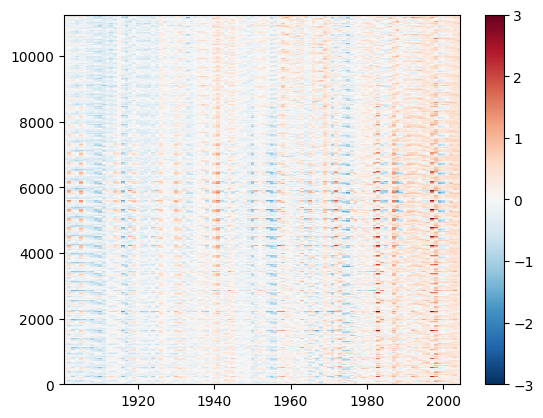

In [ ]:
# anomalies: every column has zero mean
Y = Y - Y.mean(axis=0)
M = Y.shape[1]
print(f"N = {N} years, M = {M} grid points")

plt.pcolormesh(year,np.arange(Y.shape[1]), Y.T,cmap=plt.cm.RdBu_r);
plt.clim([-3,3])
plt.colorbar();

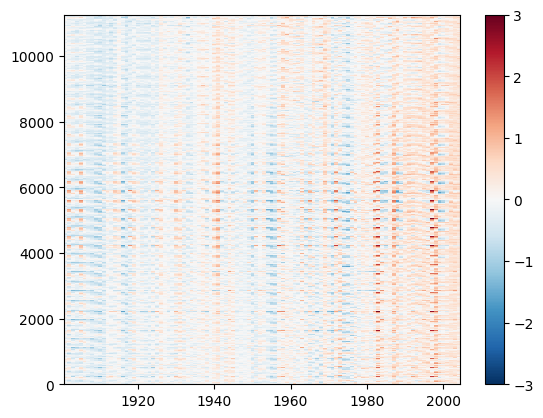

In [21]:
# Area weighting
latgrid = np.repeat(lat, nx)[ocean]
w = np.sqrt(np.cos(np.deg2rad(latgrid)))     # W^(1/2)
Yw = Y * w
plt.pcolormesh(year,np.arange(Y.shape[1]),Yw.T,cmap=plt.cm.RdBu_r);
plt.clim([-3,3])
plt.colorbar();

U: (104, 104)  s: (104,)  Vt: (104, 11264)


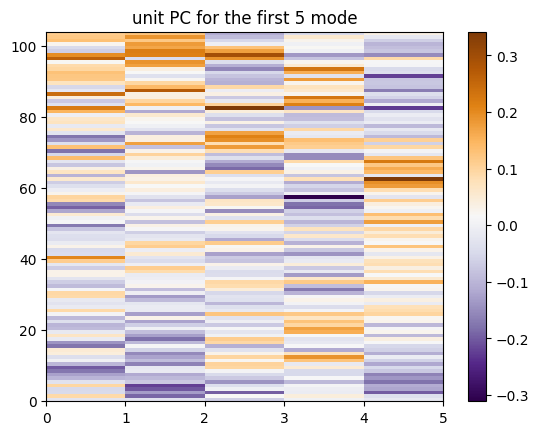

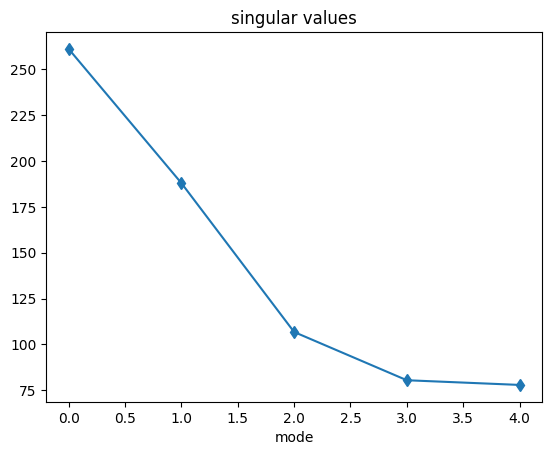

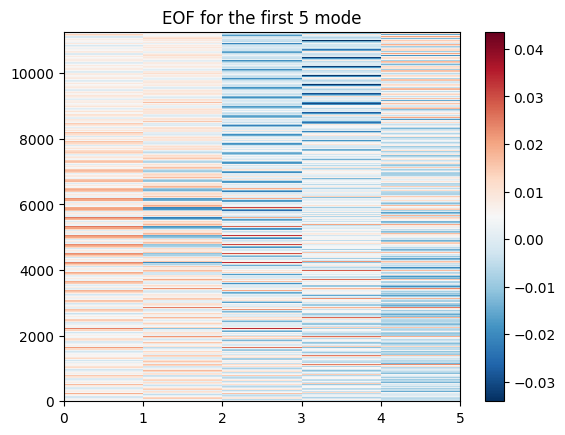

In [22]:
# SVD: Yw = U S V^T
U, s, Vt = np.linalg.svd(Yw, full_matrices=False)
print("U:", U.shape, " s:", s.shape, " Vt:", Vt.shape)

K = 5
plt.pcolormesh(U[:,:K],cmap=plt.cm.PuOr_r)
plt.title('unit PC for the first '+str(K)+' mode')
plt.colorbar()

plt.figure()
plt.plot(np.arange(K),s[:K],'d-')
plt.xlabel('mode')
plt.title('singular values')

plt.figure()
plt.pcolormesh(Vt[:K,:].T,cmap=plt.cm.RdBu_r)
plt.title('EOF for the first '+str(K)+' mode')
plt.colorbar()

In [23]:
# Variance explained
var_frac = s**2 / np.sum(s**2)
# 1 standard error of varaince for Gaussian for large N ~ sigma*sqrt(2/N)
north_err = var_frac * np.sqrt(2/ N)
for k in range(5):
    print(f"Mode {k+1}: {100*var_frac[k]:5.1f}% ± {100*north_err[k]:.1f}%")

Mode 1:  43.8% ± 6.1%
Mode 2:  22.7% ± 3.2%
Mode 3:   7.3% ± 1.0%
Mode 4:   4.2% ± 0.6%
Mode 5:   3.9% ± 0.5%


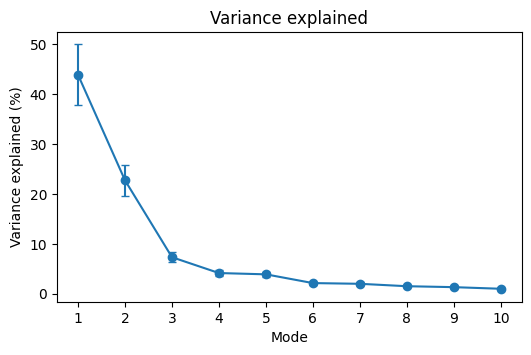

In [24]:
fig, ax = plt.subplots(figsize=(6, 3.5))
k = np.arange(1, 11)
ax.errorbar(k, 100*var_frac[:10], yerr=100*north_err[:10], fmt="o-", capsize=3)
ax.set_xlabel("Mode"); ax.set_ylabel("Variance explained (%)"); ax.set_xticks(k)
ax.set_title("Variance explained")
plt.show()

In [25]:
# PCs and EOF maps
def to_map(v):                                    # put ocean points back on the grid
    m = np.full(ny * nx, np.nan); m[ocean] = v
    return m.reshape(ny, nx)

In [26]:
K = 5
# (N, K) standardized PCs
F = np.sqrt(N - 1) * U[:, :K]
# (M, K) regression maps, °C per unit PC
E = Vt[:K].T * s[:K] / np.sqrt(N - 1)

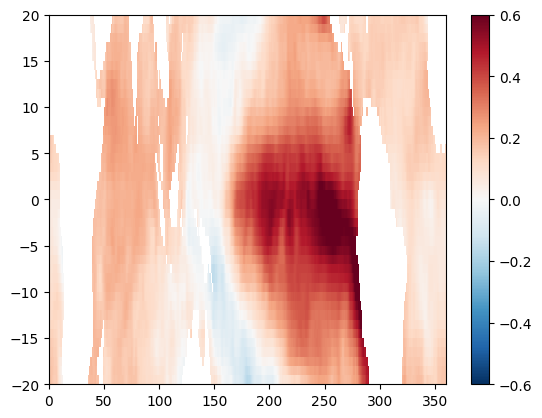

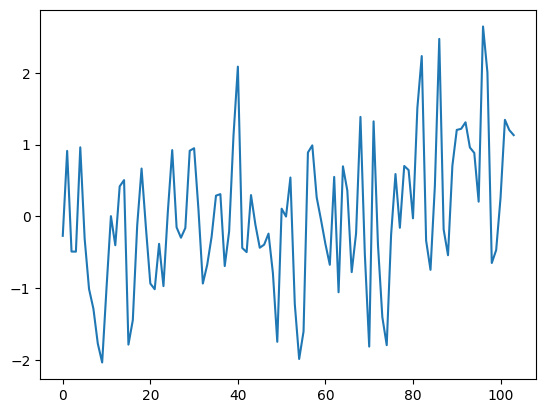

In [ ]:
plt.pcolormesh(lon, lat, to_map(E[:, 0]), cmap="RdBu_r", vmin=-0.6, vmax=0.6)
plt.colorbar()

plt.figure()
plt.plot(F[:,0])
#plt.plot(U[:,0])

In [27]:
# Fix the arbitrary sign and find the ENSO mode (largest correlation with Niño 3.4)
lon_pts = np.tile(lon, ny)[ocean]
n34_pts = (np.abs(latgrid) <= 5) & (lon_pts >= 190) & (lon_pts <= 240)
nino34 = Y[:, n34_pts].mean(axis=1)

r = np.array([np.corrcoef(F[:, k], nino34)[0, 1] for k in range(K)])
kE = int(np.argmax(np.abs(r)))                   # ENSO-like mode
if r[kE] < 0:
    F[:, kE] *= -1; E[:, kE] *= -1               # positive = El Niño
    print('test')
if kE != 0 and F[-20:, 0].mean() < 0:            # make the trend mode warm at the end
    F[:, 0] *= -1; E[:, 0] *= -1
for k in range(K):
    print(f"r(PC{k+1}, Nino3.4) = {np.corrcoef(F[:, k], nino34)[0, 1]:+.2f}")



r(PC1, Nino3.4) = +0.88
r(PC2, Nino3.4) = -0.41
r(PC3, Nino3.4) = -0.14
r(PC4, Nino3.4) = +0.04
r(PC5, Nino3.4) = +0.08


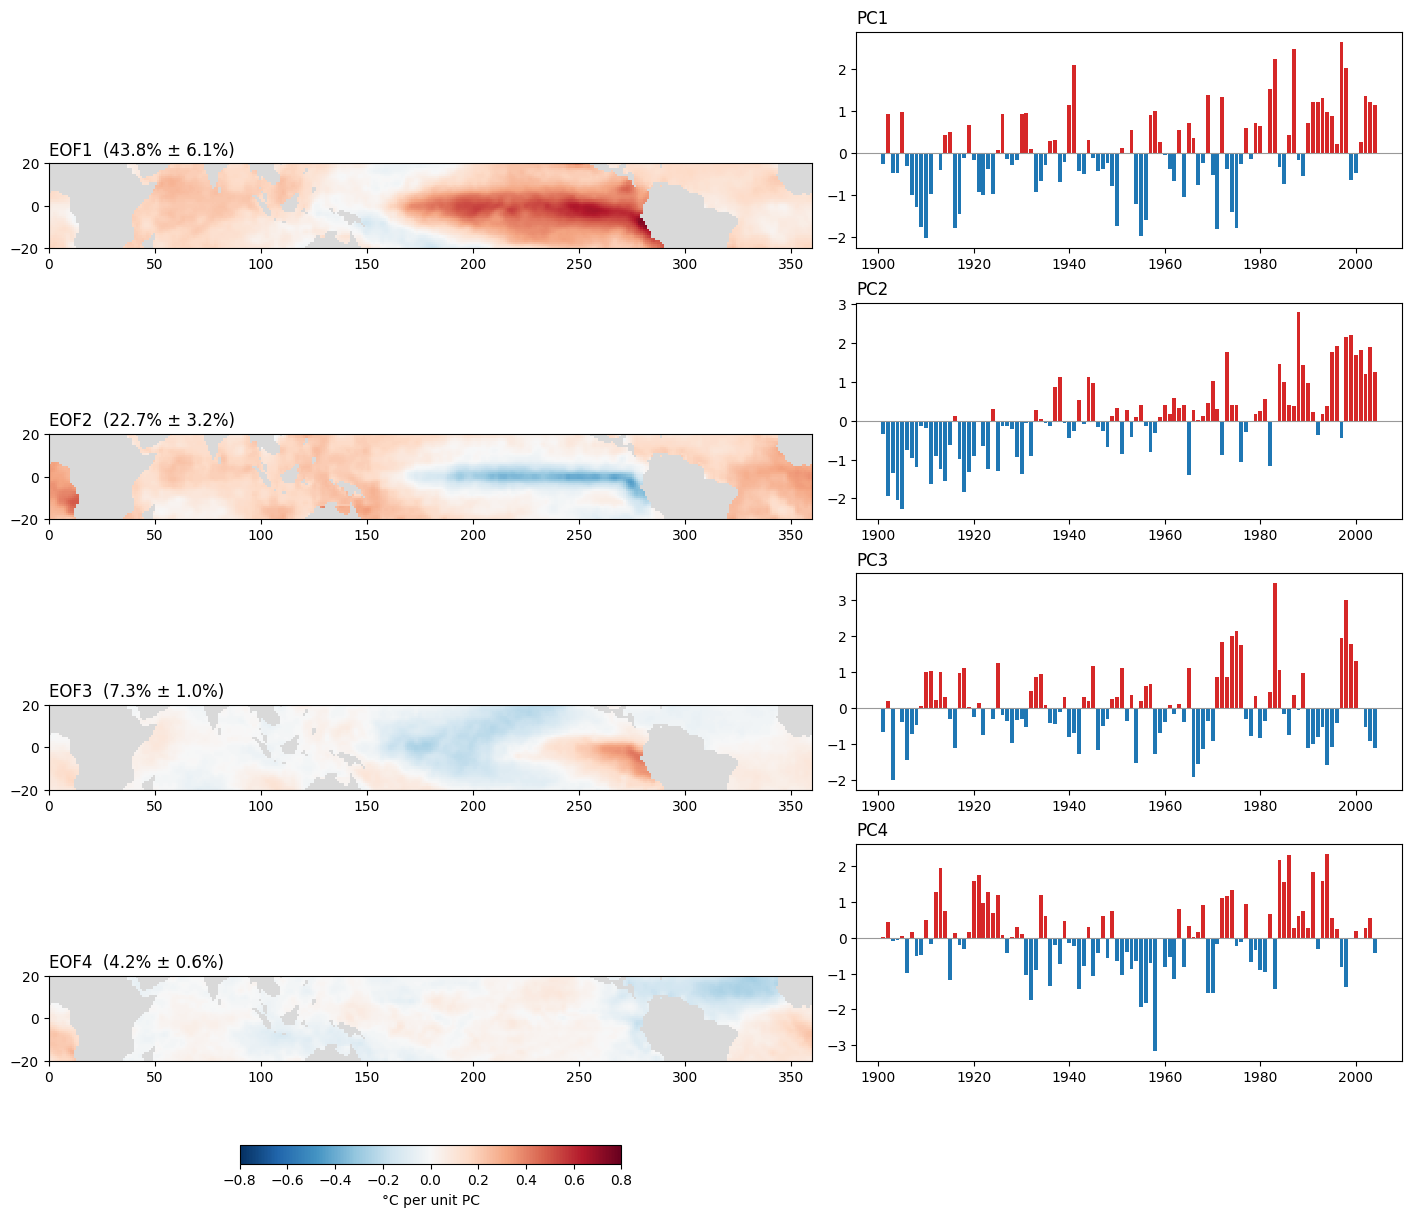

In [28]:
K = 4
fig, axs = plt.subplots(K, 2, figsize=(14, 3 * K), constrained_layout=True,
                        gridspec_kw={"width_ratios": [1.4, 1]})
for k in range(K):
    ax = axs[k, 0]; ax.set_facecolor("0.85")
    pm = ax.pcolormesh(lon, lat, to_map(E[:, k]), cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    ax.set_aspect("equal")
    ax.set_title(f"EOF{k+1}  ({100*var_frac[k]:.1f}% ± {100*north_err[k]:.1f}%)", loc="left")

    ax = axs[k, 1]
    ax.bar(year, F[:, k], color=np.where(F[:, k] > 0, "tab:red", "tab:blue"))
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set_title(f"PC{k+1}", loc="left")
fig.colorbar(pm, ax=axs[:, 0], location="bottom", shrink=0.5, label="°C per unit PC")
plt.show()

In [29]:
## check PC1 and correlation to global mean SST trend
## Since Yw is already a global data
# Tropical Pacific SST anomaly
gm_anomaly = Yw.mean(axis=1)

# SST trend
slope, intercept = np.polyfit(year, gm_anomaly, 1)
trend_line = slope * year + intercept

#Correlate
np.corrcoef(trend_line, F[:,0])[0,1]

np.float64(0.3731290037271736)

In [32]:
# Warming mode
for k in range(K):
    print(f"r(PC{k+1}, SST trend) = {np.corrcoef(trend_line, F[:, k])[0, 1]:+.2f}")


r(PC1, SST trend) = +0.37
r(PC2, SST trend) = +0.69
r(PC3, SST trend) = +0.11
r(PC4, SST trend) = +0.05
